# 1 · A PINN for potential flow past a cylinder

The network learns the stream function $\psi$ on the annulus $1 \le r \le 5$, with
$\nabla^2\psi = 0$, the body a streamline, and the exact solution as data on $r = 5$. With hard
constraints the boundary conditions hold for any network output, and only the Laplace residual
is trained. See [Lesson 1](../docs/lessons/01-pinns-for-potential-flow.md) and
[docs/pinn_laplace_2d.md](../docs/pinn_laplace_2d.md).

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

from pinncfd import io, plotting as P

torch.set_num_threads(1)  # one thread: reductions in a fixed order, reproducible outputs
P.use_style()
DEG = np.pi / 180
ROOT = Path("..").resolve()
RESULTS = ROOT / "validation" / "results"
CK = RESULTS / "checkpoints"
DEVICE = "cpu"
from pinncfd.pinn_laplace_2d import exact
from pinncfd.pinn_laplace_2d.cylinder import CylinderPINN, CylinderProblem
from pinncfd.training import TrainConfig, train

The exact solution's surface pressure integrates to $c_l = \Gamma$:

In [2]:
th = np.linspace(0, 2 * np.pi, 360, endpoint=False)
for gamma in (0.0, np.pi, 2 * np.pi):
    print(f"Gamma = {gamma:.4f}:  cl from Cp = {exact.cl_from_cp(th, exact.surface_cp(th, gamma)):.6f}")

Gamma = 0.0000:  cl from Cp = -0.000000
Gamma = 3.1416:  cl from Cp = 3.141593
Gamma = 6.2832:  cl from Cp = 6.283185


The trained networks (seed 0), evaluated on a 64 × 128 polar grid:

In [3]:
models = {}
for case in ("psi_soft", "psi_hard", "psi_hard_lifting", "phi_soft"):
    model, _ = io.load_checkpoint(CK / f"phase1_{case}.pt", CylinderPINN, DEVICE)
    models[case] = model
    m = CylinderProblem(model, n_interior=16, device=DEVICE).evaluate(model)
    print(f"{case:17s} velocity error {m['error']:.2e}   max |dCp| {m['cp_max_abs']:.2e}")

psi_soft          velocity error 1.18e-03   max |dCp| 2.38e-02
psi_hard          velocity error 8.34e-05   max |dCp| 6.02e-04
psi_hard_lifting  velocity error 6.14e-05   max |dCp| 6.14e-04
phi_soft          velocity error 1.84e-04   max |dCp| 1.86e-03


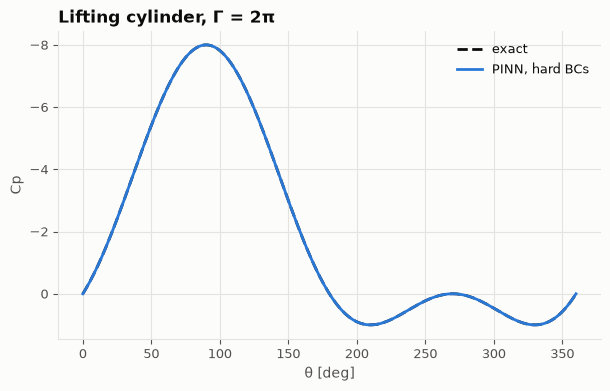

In [4]:
model = models["psi_hard_lifting"]
prob = CylinderProblem(model, n_interior=16, device=DEVICE)
th = np.linspace(0, 2 * np.pi, 361)
_, u, v = prob.predict(model, np.column_stack([np.cos(th), np.sin(th)]))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.degrees(th), exact.surface_cp(th, model.gamma), "--", color=P.REFERENCE, label="exact")
ax.plot(np.degrees(th), 1 - u**2 - v**2, color=P.SERIES[0], label="PINN, hard BCs")
ax.invert_yaxis()
ax.set_xlabel("θ [deg]"); ax.set_ylabel("Cp"); ax.set_title("Lifting cylinder, Γ = 2π"); ax.legend();

Convergence of the full runs, from the saved histories:

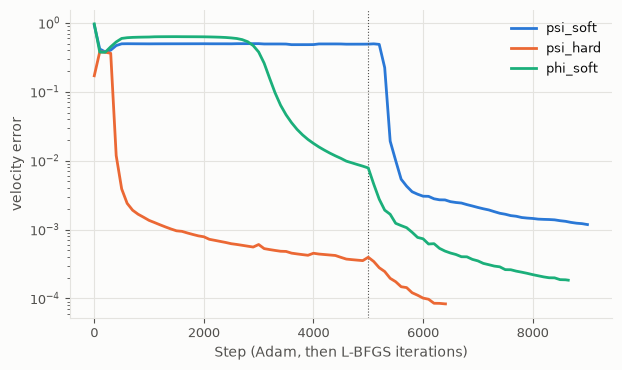

In [5]:
hist = json.loads((RESULTS / "phase1_histories.json").read_text())
fig, ax = plt.subplots(figsize=(7, 4))
for i, case in enumerate(("psi_soft", "psi_hard", "phi_soft")):
    P.convergence_plot(ax, hist[f"{case}/0"], label=case, color=P.SERIES[i],
                       adam_steps=5000 if i == 0 else None)
ax.set_ylabel("velocity error"); ax.legend();

A short training run on the CPU, with the network of the full runs (4 × 50 tanh), 1024 points, 400 Adam steps and 100 L-BFGS iterations. Watch the two columns: the loss (the Laplace residual) falls from the start, but the velocity error first *rises*, from 0.17 to 0.37, before it collapses. The full run in the plot above did the same (0.38 at step 100, 0.012 at step 400). A small residual is not yet a correct solution: the error has to be measured against a reference.

In [6]:
torch.manual_seed(0)
model = CylinderPINN(hard=True, mlp=dict(width=50, depth=4, seed=0))
prob = CylinderProblem(model, n_interior=1024, n_boundary=128, device=DEVICE)
cfg = TrainConfig(adam_steps=400, lbfgs_iters=100, eval_every=50, resample_every=0, seed=0)
res = train(model, prob, cfg, DEVICE)
for h in res.history:
    print(f"step {h['step']:4d} ({h['stage']:6s})  loss {h['loss']:.3e}   velocity error {h['error']:.3e}")

step    0 (init  )  loss 2.248e-01   velocity error 1.708e-01
step   50 (adam  )  loss 1.190e-01   velocity error 2.680e-01
step  100 (adam  )  loss 9.229e-02   velocity error 3.406e-01
step  150 (adam  )  loss 8.765e-02   velocity error 3.731e-01
step  200 (adam  )  loss 8.714e-02   velocity error 3.721e-01
step  250 (adam  )  loss 8.680e-02   velocity error 3.723e-01
step  300 (adam  )  loss 8.654e-02   velocity error 3.721e-01
step  350 (adam  )  loss 8.633e-02   velocity error 3.719e-01
step  400 (adam  )  loss 8.613e-02   velocity error 3.717e-01
step  450 (lbfgs )  loss 2.773e-03   velocity error 2.799e-02
step  500 (lbfgs )  loss 1.131e-04   velocity error 3.648e-03
